# 05. Feature selection và dimensionality reduction

Xem kết quả đã chạy của **Kinematic, MOMENT, GAF/ViT-B16, CWT/EfficientNet-B4**.
Notebook chỉ đọc artifact; không fit lại PCA, selector hoặc classifier.
216 cấu hình gồm 12 baseline OOF cũ và 204 cấu hình giảm chiều.

Các bảng xếp hạng là **thăm dò trên cùng 6 fold**, có thiên lệch chọn cấu hình.
Xem notebook **06** để đánh giá quy trình chọn bằng nested CV.
Bảng số đầu notebook giữ metric ở thang 0–1 như CSV gốc; biểu đồ dùng %.
Uncertainty là SD giữa 6 fold, không phải CI.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.float_format', '{:.6f}'.format)

ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
OUT = ROOT / 'results/feature_optimization'
validation = json.loads((OUT / 'validation.json').read_text(encoding='utf-8'))
assert validation['complete'], 'Hoàn tất và validate thực nghiệm trước khi xem.'
summary = pd.read_csv(OUT / 'summary.csv')
BRANCHES = ['Kinematic', 'MOMENT', 'GAF', 'CWT']
METRICS = [('accuracy', 'Accuracy'), ('f1_macro', 'F1 macro'), ('auc', 'ROC-AUC')]
COLORS = {'none':'#555555', 'pca':'#0072B2', 'anova':'#D55E00', 'extratrees':'#009E73'}
FIG = OUT / 'figures'
FIG.mkdir(exist_ok=True)
exports = []
plt.rcParams.update({'font.size':10, 'axes.spines.top':False,
                     'axes.spines.right':False, 'svg.fonttype':'none'})

def show(fig, name, description, sources):
    for ext in ('png', 'svg'):
        fig.savefig(FIG / f'{name}.{ext}', dpi=180, facecolor='white')
    exports.append(dict(name=name, description=description, sources=sources,
                        formats=['png','svg'], n_participants=258,
                        uncertainty='Fold SD where shown; not a confidence interval'))
    plt.show()
    plt.close(fig)

def save_manifest(name):
    for item in exports:
        item['source_sha256']={p:hashlib.sha256((OUT/p).read_bytes()).hexdigest()
                               for p in item['sources']}
    (FIG / name).write_text(json.dumps(exports, ensure_ascii=False, indent=2), encoding='utf-8')

print('Project:', ROOT)
print('Validated configurations:', len(summary), '| Participants: 258 | Outer folds: 6 | Seed: 42')

Project: E:\DiaGraMo-project
Validated configurations: 216 | Participants: 258 | Outer folds: 6 | Seed: 42


## Kết quả cuối cùng dạng số — Top 20 cấu hình

Bảng DataFrame thuần số như notebook đánh giá cũ. `accuracy`, `f1_macro`, `auc`,
v.v. là metric tính gộp từ OOF; `mean_*` và `std_*` là trung bình và SD giữa 6 fold.
Tất cả giữ thang **0–1**, không nhân 100. `mean_features` là số chiều thực tế
trung bình sau tiền xử lý/giảm chiều; `raw_features` là chiều đầu vào gốc.

Xếp theo **mean F1 macro**, rồi mean Accuracy và mean AUC, đúng tiêu chí thực nghiệm.
Đây là bảng thăm dò; bảng kết luận về quy trình chọn nằm đầu notebook 06.

In [2]:
result_columns = ['representation','reducer','classifier','raw_features','mean_features',
                  'accuracy','f1_macro','f1_weighted','f1_binary','auc','balanced_accuracy',
                  'mean_accuracy','mean_f1_macro','mean_auc',
                  'std_accuracy','std_f1_macro','std_auc']
final_results = summary.sort_values(
    ['mean_f1_macro','mean_accuracy','mean_auc'], ascending=False
)[result_columns].reset_index(drop=True)
final_results.head(20)

,representation,reducer,classifier,raw_features,mean_features,accuracy,f1_macro,f1_weighted,f1_binary,auc,balanced_accuracy,mean_accuracy,mean_f1_macro,mean_auc,std_accuracy,std_f1_macro,std_auc
0,kinematic,none,LightGBM,1036,1027.666667,0.848837,0.847163,0.848899,0.863158,0.906902,0.847461,0.848837,0.847047,0.904027,0.032056,0.032387,0.031284
1,kinematic,extratrees_512,LightGBM,1036,512.000000,0.829457,0.827120,0.829302,0.847222,0.907327,0.826573,0.829457,0.827022,0.905848,0.037977,0.038042,0.029155
2,kinematic,extratrees_512,SVM,1036,512.000000,0.829457,0.824815,0.827910,0.853333,0.883065,0.821465,0.829457,0.824220,0.887157,0.040725,0.042544,0.060478
3,kinematic,extratrees_256,LightGBM,1036,256.000000,0.821705,0.819580,0.821705,0.839161,0.901125,0.819580,0.821705,0.819465,0.895620,0.035013,0.035133,0.025709
4,kinematic,anova_256,SVM,1036,256.000000,0.821705,0.817314,0.820388,0.845638,0.867741,0.814472,0.821705,0.816076,0.873675,0.045730,0.048839,0.067808
5,kinematic,anova_512,SVM,1036,512.000000,0.821705,0.815852,0.819415,0.848684,0.871754,0.811919,0.821705,0.815369,0.877285,0.045730,0.046758,0.066064
6,kinematic,extratrees_256,SVM,1036,256.000000,0.817829,0.811576,0.815302,0.845902,0.879477,0.807571,0.817829,0.810956,0.881671,0.045135,0.045819,0.070344
7,kinematic,anova_512,LightGBM,1036,512.000000,0.810078,0.808556,0.810408,0.825623,0.901672,0.809942,0.810078,0.808198,0.900032,0.047471,0.048688,0.040502
8,kinematic,anova_256,LightGBM,1036,256.000000,0.810078,0.808277,0.810294,0.826855,0.874430,0.809091,0.810078,0.808145,0.874847,0.030911,0.031097,0.029709
9,kinematic,extratrees_128,LightGBM,1036,128.000000,0.810078,0.807295,0.809808,0.830450,0.890544,0.806537,0.810078,0.806636,0.883985,0.061382,0.063478,0.035060


## Kết quả tốt nhất từng nhánh — bao gồm lựa chọn giữ baseline

Chọn trong các cấu hình đã khảo sát, gồm `none`. Vì vậy Kinematic có thể giữ
baseline đầy đủ chiều nếu giảm chiều không tốt hơn. Vẫn là xếp hạng thăm dò.

In [3]:
best_final = summary.sort_values(
    ['mean_f1_macro','mean_accuracy','mean_auc'], ascending=False
).groupby('branch', sort=False).head(1)
best_final.set_index('branch').loc[BRANCHES].reset_index()[['branch']+result_columns]

,branch,representation,reducer,classifier,raw_features,mean_features,accuracy,f1_macro,f1_weighted,f1_binary,auc,balanced_accuracy,mean_accuracy,mean_f1_macro,mean_auc,std_accuracy,std_f1_macro,std_auc
0,Kinematic,kinematic,none,LightGBM,1036,1027.666667,0.848837,0.847163,0.848899,0.863158,0.906902,0.847461,0.848837,0.847047,0.904027,0.032056,0.032387,0.031284
1,MOMENT,moment,anova_64,LogisticRegression,14336,64.000000,0.717054,0.713921,0.717170,0.743860,0.754819,0.714108,0.717054,0.713648,0.755927,0.059594,0.057759,0.071717
2,GAF,gaf_vit_b_16,anova_256,SVM,10752,256.000000,0.670543,0.661130,0.667259,0.717608,0.669565,0.660231,0.670543,0.660025,0.661721,0.063120,0.058237,0.062542
3,CWT,cwt_efficientnet_b4,pca_var99,LogisticRegression,25088,203.333333,0.713178,0.710675,0.713596,0.737589,0.760231,0.711462,0.713178,0.707372,0.760676,0.065227,0.067500,0.060859


## Toàn bộ 216 cấu hình — đầy đủ bảng số

Không cắt hàng hoặc cột; có thể dùng tìm kiếm trong output để tìm reducer/classifier.
Để lọc thủ công, ví dụ: `final_results.query("representation == 'moment'")`.

In [4]:
with pd.option_context('display.max_rows', None):
    display(final_results)

,representation,reducer,classifier,raw_features,mean_features,accuracy,f1_macro,f1_weighted,f1_binary,auc,balanced_accuracy,mean_accuracy,mean_f1_macro,mean_auc,std_accuracy,std_f1_macro,std_auc
0,kinematic,none,LightGBM,1036,1027.666667,0.848837,0.847163,0.848899,0.863158,0.906902,0.847461,0.848837,0.847047,0.904027,0.032056,0.032387,0.031284
1,kinematic,extratrees_512,LightGBM,1036,512.000000,0.829457,0.827120,0.829302,0.847222,0.907327,0.826573,0.829457,0.827022,0.905848,0.037977,0.038042,0.029155
2,kinematic,extratrees_512,SVM,1036,512.000000,0.829457,0.824815,0.827910,0.853333,0.883065,0.821465,0.829457,0.824220,0.887157,0.040725,0.042544,0.060478
3,kinematic,extratrees_256,LightGBM,1036,256.000000,0.821705,0.819580,0.821705,0.839161,0.901125,0.819580,0.821705,0.819465,0.895620,0.035013,0.035133,0.025709
4,kinematic,anova_256,SVM,1036,256.000000,0.821705,0.817314,0.820388,0.845638,0.867741,0.814472,0.821705,0.816076,0.873675,0.045730,0.048839,0.067808
5,kinematic,anova_512,SVM,1036,512.000000,0.821705,0.815852,0.819415,0.848684,0.871754,0.811919,0.821705,0.815369,0.877285,0.045730,0.046758,0.066064
6,kinematic,extratrees_256,SVM,1036,256.000000,0.817829,0.811576,0.815302,0.845902,0.879477,0.807571,0.817829,0.810956,0.881671,0.045135,0.045819,0.070344
7,kinematic,anova_512,LightGBM,1036,512.000000,0.810078,0.808556,0.810408,0.825623,0.901672,0.809942,0.810078,0.808198,0.900032,0.047471,0.048688,0.040502
8,kinematic,anova_256,LightGBM,1036,256.000000,0.810078,0.808277,0.810294,0.826855,0.874430,0.809091,0.810078,0.808145,0.874847,0.030911,0.031097,0.029709
9,kinematic,extratrees_128,LightGBM,1036,128.000000,0.810078,0.807295,0.809808,0.830450,0.890544,0.806537,0.810078,0.806636,0.883985,0.061382,0.063478,0.035060


## Bảng so sánh với baseline cũ tốt nhất

Xếp hạng bằng mean F1 macro, rồi Accuracy và AUC. Baseline tốt nhất cũ có thể
dùng classifier khác; bảng cùng classifier ở cell dưới giúp tách hai ảnh hưởng.

In [5]:
best = pd.read_csv(OUT / 'best_per_branch.csv').set_index('branch').loc[BRANCHES].reset_index()
cols = ['branch','reducer','classifier','raw_features','mean_features','old_best_classifier']
table = best[cols].copy()
for m, label in METRICS:
    table['Old '+label+' (%)'] = 100*best['old_best_mean_'+m]
    table['New '+label+' (%)'] = 100*best['mean_'+m]
display(table.round(2))
same = pd.read_csv(OUT / 'comparison_same_classifier.csv')
display(best[['branch','reducer','classifier','delta_f1_macro_pp',
              'delta_vs_old_best_f1_macro_pp']].round(2))

,branch,reducer,classifier,raw_features,mean_features,old_best_classifier,Old Accuracy (%),New Accuracy (%),Old F1 macro (%),New F1 macro (%),Old ROC-AUC (%),New ROC-AUC (%)
0,Kinematic,extratrees_512,LightGBM,1036,512.000000,LightGBM,84.880000,82.950000,84.700000,82.700000,90.400000,90.580000
1,MOMENT,anova_64,LogisticRegression,14336,64.000000,SVM,67.830000,71.710000,64.790000,71.360000,75.070000,75.590000
2,GAF,anova_256,SVM,10752,256.000000,LightGBM,63.180000,67.050000,61.650000,66.000000,66.300000,66.170000
3,CWT,pca_var99,LogisticRegression,25088,203.330000,LogisticRegression,68.600000,71.320000,68.100000,70.740000,75.850000,76.070000


,branch,reducer,classifier,delta_f1_macro_pp,delta_vs_old_best_f1_macro_pp
0,Kinematic,extratrees_512,LightGBM,-2.000000,-2.000000
1,MOMENT,anova_64,LogisticRegression,9.240000,6.570000
2,GAF,anova_256,SVM,5.310000,4.350000
3,CWT,pca_var99,LogisticRegression,2.630000,2.630000


## Chênh lệch so với baseline cùng classifier — bảng số

Chỉ so sánh các cấu hình dùng cùng classifier. Metric giữ thang 0–1;
các cột `delta_*_pp` là chênh lệch **điểm phần trăm**. Bảng này gồm
ứng viên giảm chiều có F1 cao nhất cho từng cặp nhánh/classifier.

In [6]:
same_best = same.sort_values(
    ['mean_f1_macro','mean_accuracy','mean_auc'], ascending=False
).groupby(['branch','classifier'], sort=False).head(1)
same_columns = ['branch','reducer','classifier','mean_features']
for m, _ in METRICS:
    same_columns += ['baseline_mean_'+m, 'mean_'+m, 'delta_'+m+'_pp']
same_best[same_columns].sort_values(['branch','classifier']).reset_index(drop=True)

,branch,reducer,classifier,mean_features,baseline_mean_accuracy,mean_accuracy,delta_accuracy_pp,baseline_mean_f1_macro,mean_f1_macro,delta_f1_macro_pp,baseline_mean_auc,mean_auc,delta_auc_pp
0,CWT,extratrees_64,LightGBM,64.000000,0.635659,0.662791,2.713178,0.625021,0.653294,2.827318,0.698201,0.694384,-0.381706
1,CWT,pca_var99,LogisticRegression,203.333333,0.686047,0.713178,2.713178,0.681032,0.707372,2.633966,0.758514,0.760676,0.216120
2,CWT,pca_var95,SVM,169.000000,0.651163,0.674419,2.325581,0.611936,0.669040,5.710427,0.730432,0.724606,-0.582571
3,GAF,anova_128,LightGBM,128.000000,0.631783,0.635659,0.387597,0.616533,0.624675,0.814180,0.663024,0.651166,-1.185800
4,GAF,pca_16,LogisticRegression,16.000000,0.565891,0.658915,9.302326,0.555888,0.645201,8.931354,0.603331,0.707879,10.454805
5,GAF,anova_256,SVM,256.000000,0.647287,0.670543,2.325581,0.606955,0.660025,5.306929,0.674959,0.661721,-1.323735
6,Kinematic,extratrees_512,LightGBM,512.000000,0.848837,0.829457,-1.937984,0.847047,0.827022,-2.002481,0.904027,0.905848,0.182113
7,Kinematic,extratrees_128,LogisticRegression,128.000000,0.782946,0.802326,1.937984,0.780886,0.799660,1.877420,0.863441,0.838730,-2.471078
8,Kinematic,extratrees_512,SVM,512.000000,0.798450,0.829457,3.100775,0.788802,0.824220,3.541846,0.863018,0.887157,2.413870
9,MOMENT,anova_128,LightGBM,128.000000,0.631783,0.682171,5.038760,0.616656,0.674489,5.783255,0.641298,0.723474,8.217646


## Các phương pháp trên cùng một thang đo

Mỗi cột là cấu hình có mean F1 macro cao nhất trong một phương pháp/nhánh,
bao gồm baseline trong ba classifier đang khảo sát. Thanh sai số là SD của
metric tương ứng. Chọn theo F1 nên cột Accuracy/AUC không phải cực đại riêng.

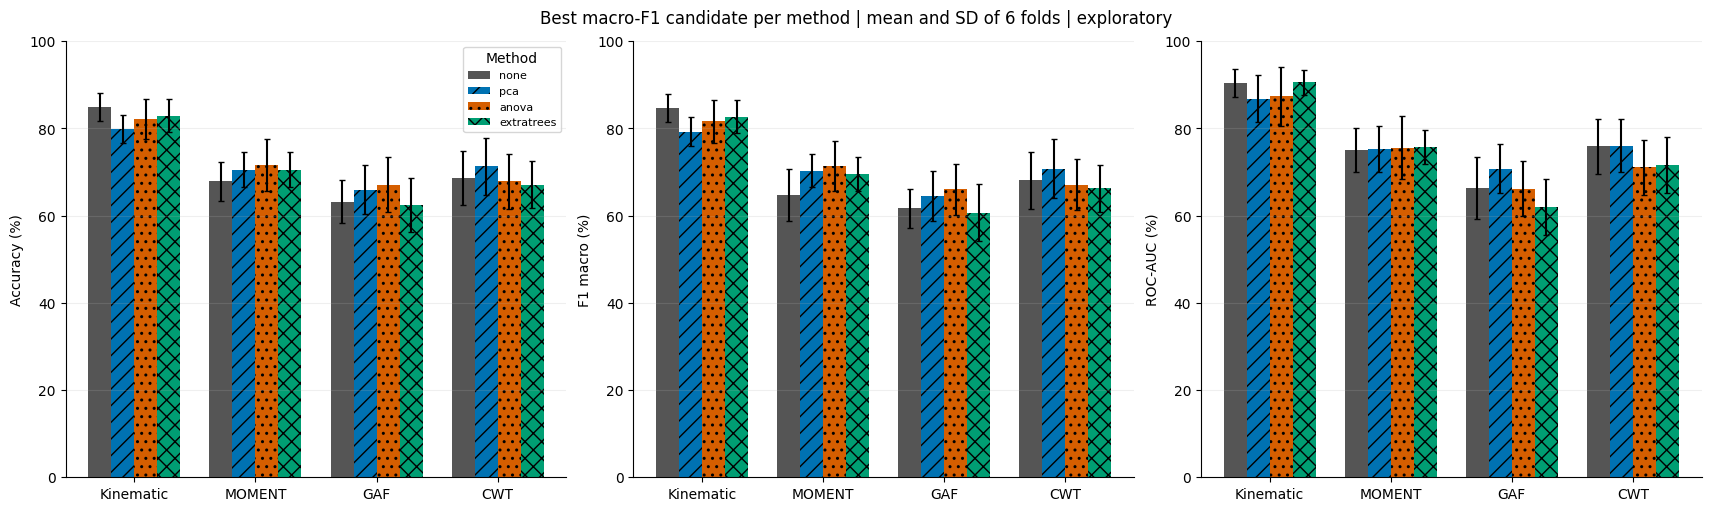

,branch,method,reducer,classifier,mean_features,mean_accuracy,mean_f1_macro,mean_auc
108,Kinematic,none,none,LightGBM,1027.666700,0.848800,0.847000,0.904000
109,Kinematic,extratrees,extratrees_512,LightGBM,512.000000,0.829500,0.827000,0.905800
112,Kinematic,anova,anova_256,SVM,256.000000,0.821700,0.816100,0.873700
121,Kinematic,pca,pca_var90,SVM,101.500000,0.798400,0.792500,0.868500
162,MOMENT,anova,anova_64,LogisticRegression,64.000000,0.717100,0.713600,0.755900
0,CWT,pca,pca_var99,LogisticRegression,203.333300,0.713200,0.707400,0.760700
163,MOMENT,pca,pca_var99,SVM,203.000000,0.705400,0.702900,0.752900
164,MOMENT,extratrees,extratrees_512,SVM,512.000000,0.705400,0.695000,0.757300
2,CWT,none,none,LogisticRegression,25088.000000,0.686000,0.681000,0.758500
4,CWT,anova,anova_512,LogisticRegression,512.000000,0.678300,0.671300,0.711100


In [7]:
ranked = summary.sort_values(['mean_f1_macro','mean_accuracy','mean_auc'], ascending=False)
winners = ranked.groupby(['branch','method'], sort=False).head(1)
methods = ['none','pca','anova','extratrees']
fig, axes = plt.subplots(1,3,figsize=(17,5),layout='constrained')
x = np.arange(4); width = .19
for ax,(m,label) in zip(axes,METRICS):
    for j, method in enumerate(methods):
        g = winners[winners.method==method].set_index('branch').loc[BRANCHES]
        ax.bar(x+(j-1.5)*width,100*g['mean_'+m],width,
               yerr=100*g['std_'+m],capsize=2,label=method,
               color=COLORS[method],hatch=['','//','..','xx'][j])
    ax.set(xticks=x,xticklabels=BRANCHES,ylim=(0,100),ylabel=label+' (%)')
    ax.grid(axis='y',alpha=.2)
axes[0].legend(title='Method',fontsize=8)
fig.suptitle('Best macro-F1 candidate per method | mean and SD of 6 folds | exploratory')
show(fig,'method_comparison','Method winners chosen by macro-F1; bars show each metric and fold SD.', ['summary.csv'])
display(winners[['branch','method','reducer','classifier','mean_features',
                 'mean_accuracy','mean_f1_macro','mean_auc']].round(4))

## Mức giảm chiều và hiệu năng — hiển thị mọi cấu hình

Mỗi hàng là reducer, mỗi cột là classifier; không chỉ hiển thị cấu hình thắng.
Các panel dùng chung thang màu F1 macro 0–100%. Tên PCA `var90/95/99` là tỷ lệ
phương sai train, số thành phần thực tế thay đổi theo fold.

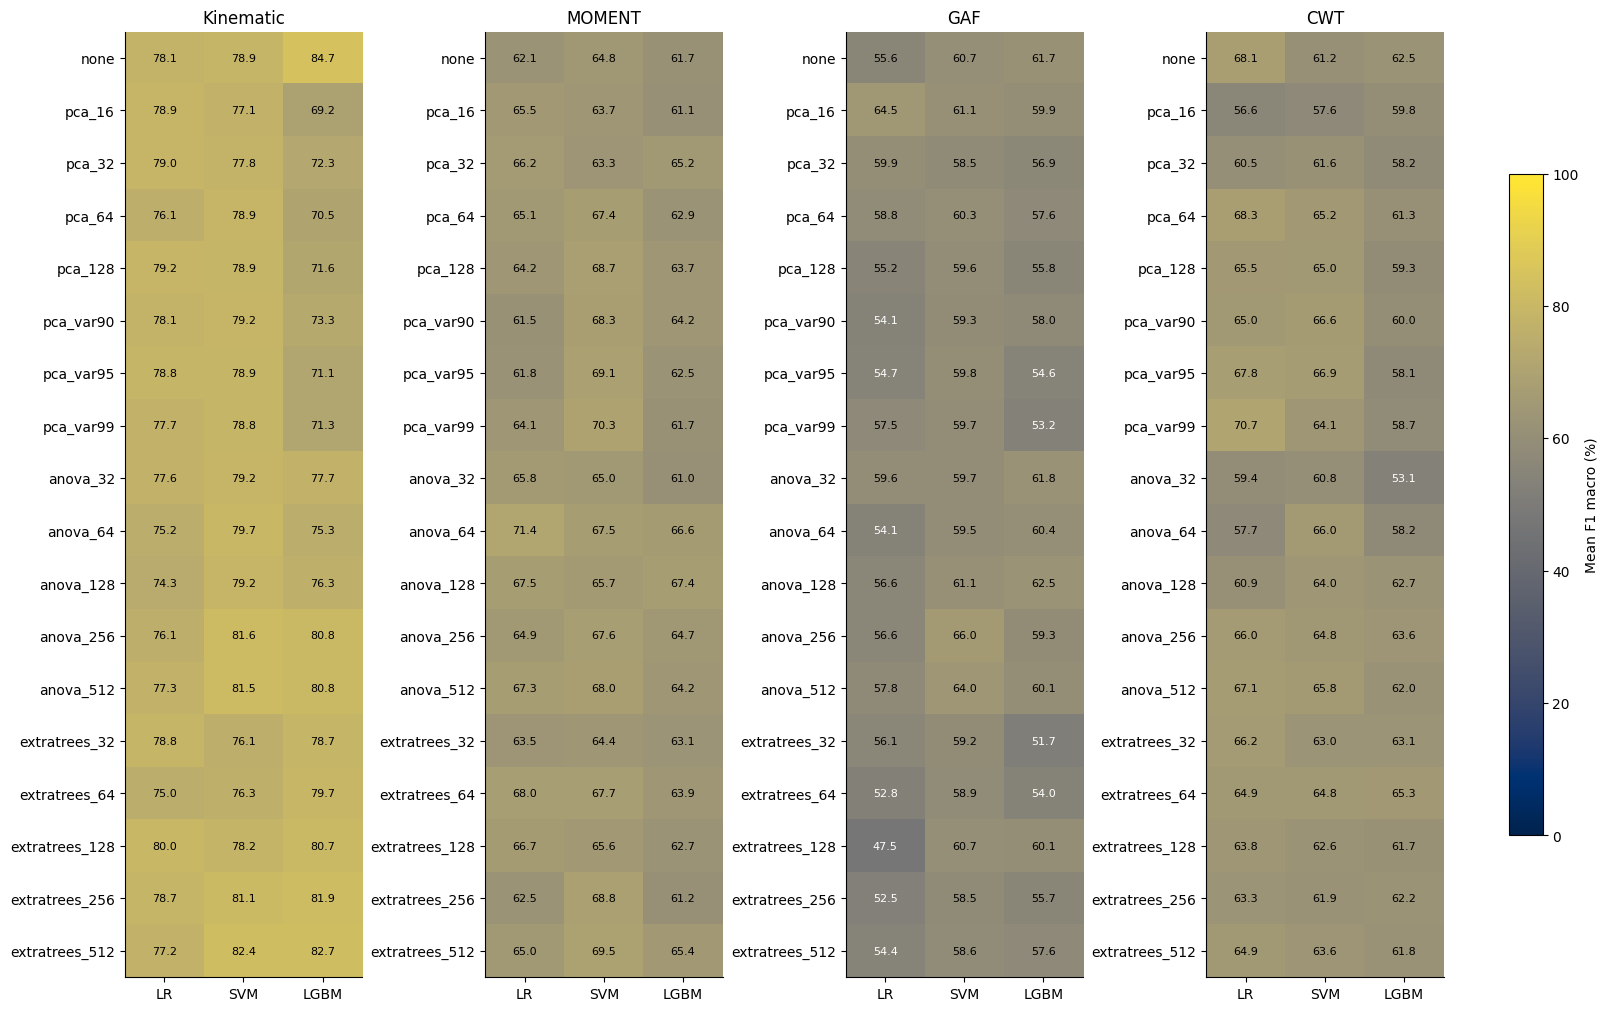

In [8]:
reducers = ['none','pca_16','pca_32','pca_64','pca_128','pca_var90','pca_var95','pca_var99',
            'anova_32','anova_64','anova_128','anova_256','anova_512',
            'extratrees_32','extratrees_64','extratrees_128','extratrees_256','extratrees_512']
classifiers = ['LogisticRegression','SVM','LightGBM']
fig, axes = plt.subplots(1,4,figsize=(16,10),layout='constrained')
for ax,branch in zip(axes,BRANCHES):
    grid = summary[summary.branch==branch].pivot(index='reducer',columns='classifier',values='mean_f1_macro')
    grid = 100*grid.reindex(index=reducers,columns=classifiers)
    assert not grid.isna().any().any()
    im = ax.imshow(grid.to_numpy(),vmin=0,vmax=100,cmap='cividis',aspect='auto')
    for i in range(len(reducers)):
        for j in range(3):
            v = grid.iloc[i,j]
            ax.text(j,i,f'{v:.1f}',ha='center',va='center',fontsize=8,
                    color='black' if v>55 else 'white')
    ax.set(title=branch,xticks=range(3),xticklabels=['LR','SVM','LGBM'],
           yticks=range(len(reducers)),yticklabels=reducers)
fig.colorbar(im,ax=axes,label='Mean F1 macro (%)',shrink=.7)
show(fig,'all_configurations','All 216 candidates; shared F1 color limits, annotated values.', ['summary.csv'])

## Đường cong theo số chiều

Giữ classifier riêng trên từng panel. PCA phương sai được hiển thị ở bảng,
không trộn vào đường PCA số chiều cố định. Đường ngang là baseline cùng classifier.
Trục x log₁₀; trục y dùng toàn khoảng 0–100%.

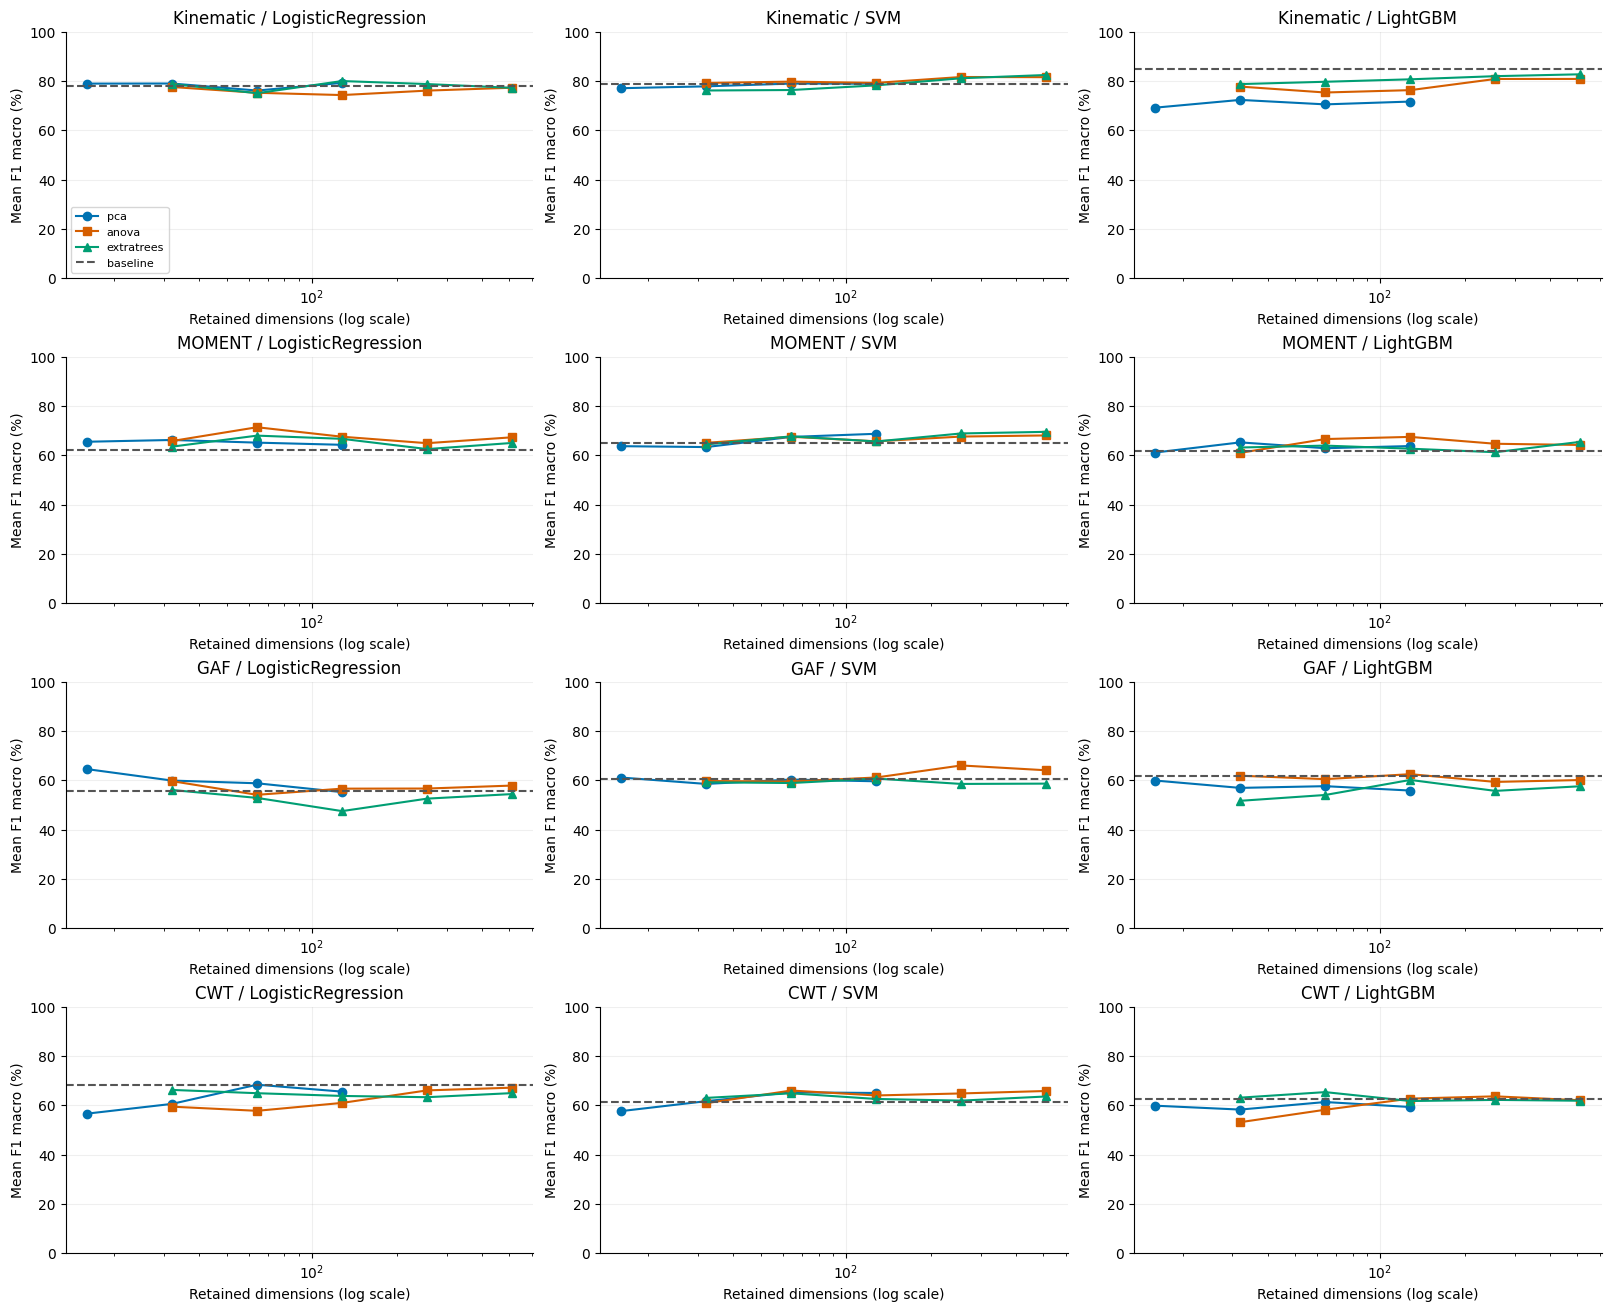

,branch,reducer,classifier,min_features,max_features,mean_explained_variance,mean_f1_macro
0,CWT,pca_var99,LogisticRegression,203,204,0.990400,0.707400
3,CWT,pca_var95,LogisticRegression,169,169,0.950800,0.678000
5,CWT,pca_var95,SVM,169,169,0.950800,0.669000
6,CWT,pca_var90,SVM,137,137,0.900900,0.665700
15,CWT,pca_var90,LogisticRegression,137,137,0.900900,0.649700
20,CWT,pca_var99,SVM,203,204,0.990400,0.641000
42,CWT,pca_var90,LightGBM,137,137,0.900900,0.600500
46,CWT,pca_var99,LightGBM,203,204,0.990400,0.587400
49,CWT,pca_var95,LightGBM,169,169,0.950800,0.580700
70,GAF,pca_var95,SVM,179,179,0.950400,0.598100


In [9]:
fig, axes = plt.subplots(4,3,figsize=(16,13),layout='constrained')
for i,branch in enumerate(BRANCHES):
    for j,clf in enumerate(classifiers):
        ax = axes[i,j]
        g = summary[(summary.branch==branch)&(summary.classifier==clf)]
        for method,marker in [('pca','o'),('anova','s'),('extratrees','^')]:
            q = g[(g.method==method)&~g.reducer.str.contains('var')].sort_values('mean_features')
            ax.plot(q.mean_features,100*q.mean_f1_macro,marker=marker,
                    color=COLORS[method],label=method)
        base = g[g.method=='none'].iloc[0]
        ax.axhline(100*base.mean_f1_macro,color=COLORS['none'],ls='--',label='baseline')
        ax.set(xscale='log',ylim=(0,100),title=branch+' / '+clf,
               xlabel='Retained dimensions (log scale)',ylabel='Mean F1 macro (%)')
        ax.grid(alpha=.2)
axes[0,0].legend(fontsize=8)
show(fig,'dimension_curves','Fixed dimension grids by branch and classifier; dashed same-classifier baseline.', ['summary.csv'])
display(summary[summary.reducer.str.contains('pca_var')][
    ['branch','reducer','classifier','min_features','max_features','mean_explained_variance','mean_f1_macro']].round(4))

## Mức nén của các ứng viên đứng đầu

Đây là giảm kích thước đầu vào classifier, chưa phải đo tốc độ toàn pipeline.
Encoder vẫn phải tạo embedding gốc. Chưa có cơ sở thay baseline chỉ từ bảng thắng.

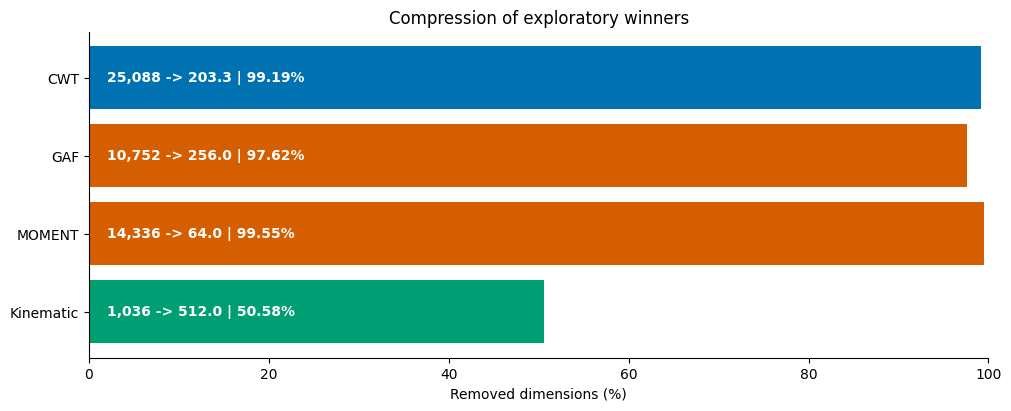

Figures: E:\DiaGraMo-project\results\feature_optimization\figures


In [10]:
fig, ax = plt.subplots(figsize=(10,4),layout='constrained')
values = best.reduction_pct.to_numpy()
ax.barh(BRANCHES,values,color=[COLORS[m] for m in best.method])
for i,r in enumerate(best.itertuples()):
    ax.text(2,i,f'{r.raw_features:,} -> {r.mean_features:.1f} | {r.reduction_pct:.2f}%',
            va='center',color='white',fontweight='bold')
ax.set(xlim=(0,100),xlabel='Removed dimensions (%)',title='Compression of exploratory winners')
show(fig,'compression','Raw versus retained feature counts for the best reduced candidate per branch.', ['best_per_branch.csv'])
save_manifest('overview_manifest.json')
print('Figures:', FIG)